# Construction of the W tables

This notebook demonstrates the construction of the two table families entering the marginalized statistic.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT/'src')); sys.path.insert(0, str(ROOT/'examples'))
import numpy as np, matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LogNorm
from exmarg import figstyle, w_table_dl, make_event, make_data, zeta
from exmarg.detectors import c as clight, x as xdet, basis
figstyle.apply()
get_ipython().run_line_magic("matplotlib","inline")
NAVY, RED = figstyle.NAVY, figstyle.RED
NSIDE = 64      # paper uses 128

/projects/standard/vuk/shared/boyb001/non_gaussian/exmarg/src/exmarg/profiles.py:14: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


## Figure 3a. The geometry tables $W^{(n)}_{ab}(\tau)$

`w_table_dl` builds them over the sky/orientation/distance quadrature at a quiet ($u=5$) and a loud ($u=100$) template.


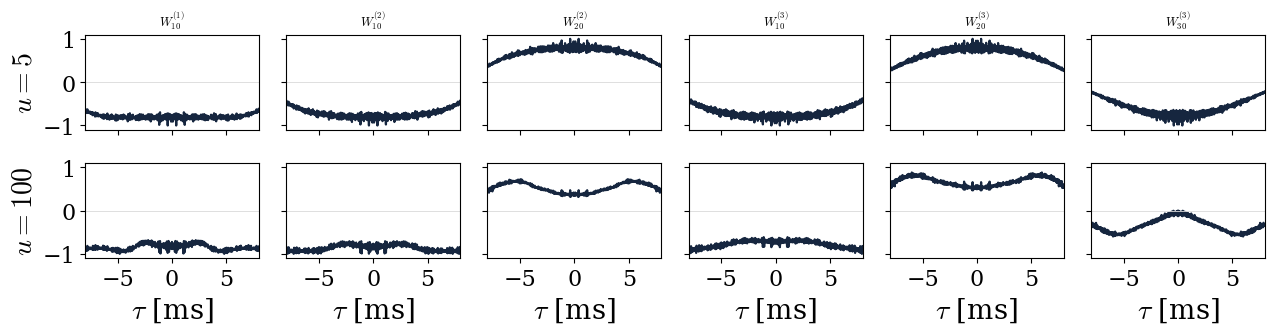

In [2]:
tau, Ws = w_table_dl(np.array([5.0, 100.0]), np.array([5.0, 100.0]),
                     0.4, 3, n_tau=513, nside=NSIDE)
KEYS = [(1,1,0),(2,1,0),(2,2,0),(3,1,0),(3,2,0),(3,3,0)]
tms = tau*1e3
fig, axs = plt.subplots(2, len(KEYS), figsize=(13, 3.6), sharex=True, sharey=True)
for r, (u, W) in enumerate(zip([5.0, 100.0], Ws)):
    for cc, key in enumerate(KEYS):
        y = W[key]/np.abs(W[key]).max()
        axs[r, cc].plot(tms, y, color=NAVY, lw=1.6); axs[r, cc].axhline(0, color='0.85', lw=0.6)
        axs[r, cc].set_xlim(-8, 8)
        if r == 0: axs[r, cc].set_title(r'$W^{(%d)}_{%d%d}$' % key, fontsize=9)
        if r == 1: axs[r, cc].set_xlabel(r'$\tau$ [ms]')
        if cc == 0: axs[r, cc].set_ylabel(r'$u=%g$' % u)
fig.tight_layout()
np.savez('data/fig3_W.npz', tau=tau, keys=np.array(KEYS),
         W5=np.array([Ws[0][k] for k in KEYS]), W100=np.array([Ws[1][k] for k in KEYS]))
plt.show()

## Figure 3b. The data tables $T^{(n)}_{ab}(\tau)$

From the matched-filter series $z_I(t)$ of one segment, $$T^{(n)}_{ab}(\tau)=\big\langle z_H^{a}\,\bar z_H^{\,b}(t+\tau)\;z_L^{\,n-a}\,\bar z_L^{\,n-b}(t)\big\rangle_t .$$ They are complex; we trace them in the complex plane over a delay window, for a noise-only and a loud signal segment.


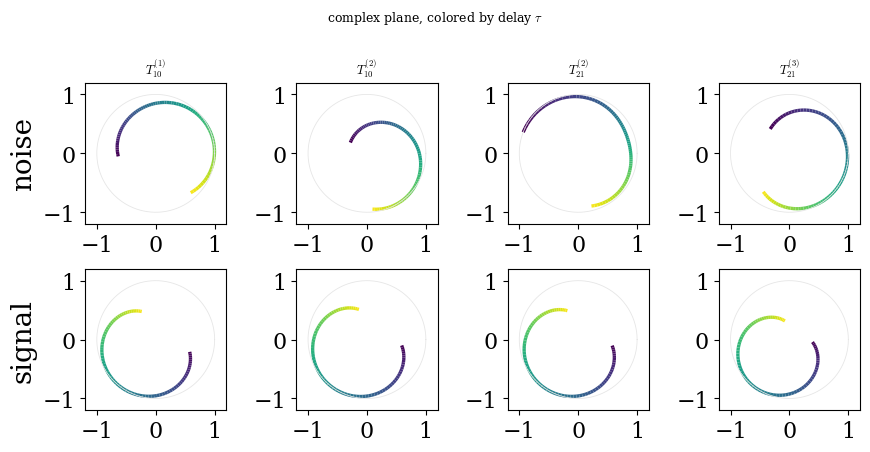

In [3]:
case = make_event(35, 30, 0.0, 0.0, 4.0, 20.0, 512.0, sky=(1.1,2.3), psi_s=0.7, chi_s=0.6)
n_hat = basis(np.array([case.sky[0]]), np.array([case.sky[1]]))[0][0]
tau_true = float(n_hat @ (xdet['H']-xdet['L'])/clight)
blocks = [('noise', make_data(case, 5, inject=False)),
          ('signal', make_data(case, 5, inject=True, t_s=3.7, y_s=60.0/case.rho_mf))]
TKEYS = [(1,1,0),(2,1,0),(2,2,1),(3,2,1)]
fig, axs = plt.subplots(2, len(TKEYS), figsize=(9, 4.6))
for r, (tag, d) in enumerate(blocks):
    t, z = zeta(case, d, oversample=32); n_time, dt = t.size, t[1]-t[0]
    sh = np.arange(int(round((tau_true-2.5e-3)/dt)), int(round((tau_true+2.5e-3)/dt))+1)
    Z1 = z['H'][(np.arange(n_time)[None,:]+sh[:,None]) % n_time]; Z2 = z['L'][None,:]
    for cc, (n,a,b) in enumerate(TKEYS):
        T = (Z1**a*np.conj(Z1)**b*Z2**(n-a)*np.conj(Z2)**(n-b)).mean(1)
        T = T/np.abs(T).max()
        pts = np.stack([T.real, T.imag], 1)[:, None, :]
        seg = np.concatenate([pts[:-1], pts[1:]], 1)
        lc = LineCollection(seg, cmap='viridis', lw=2.4); lc.set_array(sh*dt*1e3)
        axs[r, cc].add_collection(lc)
        axs[r, cc].plot(np.cos(np.linspace(0,2*np.pi,100)), np.sin(np.linspace(0,2*np.pi,100)), color='0.9', lw=0.6)
        axs[r, cc].set_xlim(-1.2,1.2); axs[r, cc].set_ylim(-1.2,1.2); axs[r, cc].set_aspect('equal')
        if r == 0: axs[r, cc].set_title(r'$T^{(%d)}_{%d%d}$'%(n,a,b), fontsize=9)
        if cc == 0: axs[r, cc].set_ylabel(tag)
fig.suptitle(r'complex plane, colored by delay $\tau$', fontsize=9); fig.tight_layout()
plt.show()

## Figure 4. Sky-quadrature convergence

The leading table $W^{(1)}_{10}$ at $u=100$ built at increasing HEALPix resolution; the shape converges.


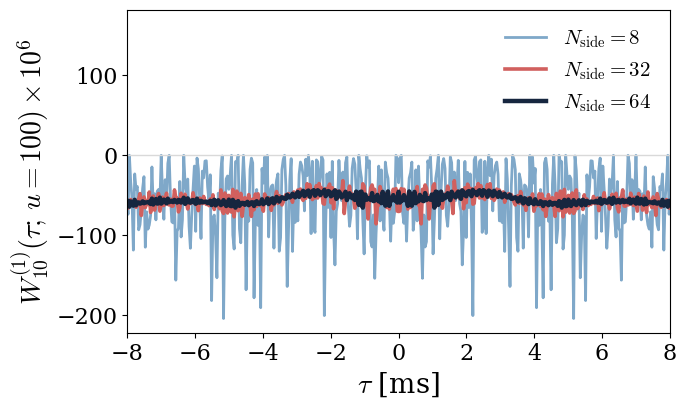

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.2)); cols = ['#7FA8C9', RED, NAVY]
rows = {}
for i, ns in enumerate([8, 32, 64]):
    tau_n, W = w_table_dl(100.0, 100.0, 0.4, 1, n_tau=513, nside=ns)
    rows[ns] = W[(1,1,0)]
    ax.plot(tau_n*1e3, 1e6*W[(1,1,0)], lw=2.0+0.6*i, color=cols[i], label=r'$N_{\rm side}=%d$'%ns)
ax.axhline(0, color='0.85', lw=1); ax.set_xlim(-8,8)
ax.set_xlabel(r'$\tau$ [ms]'); ax.set_ylabel(r'$W^{(1)}_{10}(\tau;\,u=100)\times10^{6}$')
ax.legend(frameon=False, fontsize=figstyle.FS_LEGEND)
np.savez('data/fig4_nside.npz', tau=tau_n, nsides=[8,32,64], rows=np.array([rows[n] for n in [8,32,64]]))
plt.show()

## Figure 5. The generalized overlap reduction function

We take the Fourier transform of the leading table $W^{(1)}_{10}(\tau)$ across a ladder of template loudness, $$\widetilde W^{(1)}_{10}(f)=\int d\tau\,W^{(1)}_{10}(\tau)\,e^{-2\pi i f\tau},$$ the generalized overlap reduction function.

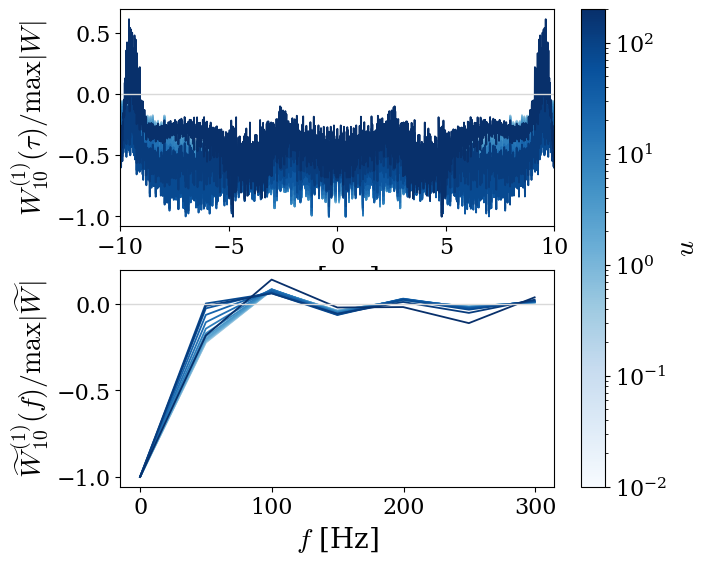

In [5]:
US = np.geomspace(0.01, 200.0, 15)
tau5, Ws5 = w_table_dl(US, US, 0.4, 1, n_tau=2049, nside=NSIDE)
rows = [W[(1,1,0)] for W in Ws5]
dtau = tau5[1]-tau5[0]
fgrid = np.fft.rfftfreq(tau5.size, d=dtau)      # Hz
gammas = [np.fft.rfft(np.fft.ifftshift(r)).real * dtau for r in rows]
keep = fgrid <= 300
cmap = plt.cm.Blues; nc = LogNorm(US.min(), US.max())
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 6.2))
for u, r in zip(US, rows):
    a1.plot(tau5*1e3, r/np.abs(r).max(), lw=1.3, color=cmap(0.3+0.7*nc(u)))
for u, g in zip(US, gammas):
    a2.plot(fgrid[keep], (g/np.abs(g).max())[keep], lw=1.3, color=cmap(0.3+0.7*nc(u)))
a1.set_xlim(-10,10); a1.axhline(0,color='0.85',lw=1); a2.axhline(0,color='0.85',lw=1)
a1.set_xlabel(r'$\tau$ [ms]'); a1.set_ylabel(r'$W^{(1)}_{10}(\tau)/\max|W|$')
a2.set_xlabel(r'$f$ [Hz]'); a2.set_ylabel(r'$\widetilde W^{(1)}_{10}(f)/\max|\widetilde W|$')
fig.colorbar(plt.cm.ScalarMappable(norm=nc, cmap=cmap), ax=[a1,a2], label=r'$u$')
np.savez('data/fig5_orf.npz', tau=tau5, us=US, rows=np.array(rows),
         fgrid=fgrid, gammas=np.array(gammas))
plt.show()